# 03 Preporuka tehnologija

Ulaz: `data/interim/dataset_kanonizovan.parquet`, koji proizvodi `02_analiza.ipynb`.

Pitanje: kandidat zna nekoliko tehnologija. Šta da uči sledeće?

Porede se tri pristupa:

1. popularnost, uvek predlaže najtraženije tehnologije, bez obzira na to šta kandidat zna
2. Apriori, pravila oblika "uz X ide Y", rangirana po pouzdanosti
3. sličnost po liftu, tehnologije koje su najjače vezane za ono što kandidat već zna

## 1. Podešavanje i učitavanje

In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

INTERIM = Path("data/interim")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)

SEED = 42

dataset = pd.read_parquet(INTERIM / "dataset_kanonizovan.parquet")
it = dataset[dataset["is_it_role"]].copy()
print(f"Učitano: {len(dataset):,} oglasa, od toga IT: {len(it):,}")

Učitano: 14,156 oglasa, od toga IT: 11,713


### Oglas kao korpa

Svaki IT oglas postaje jedna korpa, skup tehnologija koje traži. Redosled i
ponavljanje nisu bitni, pa se korpa pravi kao skup. Naziv potiče iz analize
potrošačkih korpi, gde se isti postupak koristi za pitanje "ko kupi hleb, kupi
i mleko".

In [2]:
it["korpa"] = it["tech"].apply(lambda l: sorted(set(l)) if l is not None else [])

velicina = it["korpa"].apply(len)
print(f"tehnologija po oglasu: prosek {velicina.mean():.2f}, medijana {velicina.median():.0f}")
print(f"oglasa bez ijedne tehnologije: {(velicina == 0).sum():,} ({(velicina == 0).mean()*100:.1f} %)")

tehnologija po oglasu: prosek 7.14, medijana 6
oglasa bez ijedne tehnologije: 1,080 (9.2 %)


## 2. Podela na učenje i proveru po firmi

Preporuka se uči na jednom delu oglasa, a proverava na drugom. Da je podela
nasumična po oglasu, ista firma bi završila u oba dela. Firme objavljuju više
skoro istih oglasa, isti posao u drugom gradu i sa malo drugačijim tekstom, pa
bi se proveravalo delom na oglasima koje je model već video.

Uklanjanje duplikata u `01_ekstrakcija` hvata samo identične kopije. Podela po
firmi hvata i skoro identične, jer nijedna firma nije istovremeno u učenju i u
proveri.

`GroupShuffleSplit` deli firme u odnosu 80/20, pa udeo oglasa u proveri nije
tačno 20 %.

Koliko to stvarno menja rezultat zavisi od modela. Pravila i lift se računaju iz
učestalosti na hiljadama korpi, pa jedan ponovljen oglas pomera brojanje za jedan
i skoro ništa ne menja. Merenje u sekciji 9 to proverava. Podela po firmi je
ovde ispravan postupak, a ne ispravka koja popravlja rezultat.

In [3]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

# Oglasi bez naziva firme dobijaju svaki svoju grupu, da ne bi svi završili u jednoj "firmi".
it["firma"] = it["company_name"].fillna("__bez_firme_" + it["job_id"].astype(str))


def podeli(seed: int, po_firmi: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Po firmi: 20 % firmi ide u proveru.  Nasumično: 20 % oglasa ide u proveru."""
    if po_firmi:
        podela = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
        idx_ucenje, idx_provera = next(podela.split(it, groups=it["firma"]))
        return it.iloc[idx_ucenje], it.iloc[idx_provera]
    return train_test_split(it, test_size=0.2, random_state=seed)


ucenje, provera = podeli(SEED)
assert not set(ucenje["firma"]) & set(provera["firma"]), "ista firma je u oba skupa"

print(f"učenje : {len(ucenje):>6,} oglasa  ({ucenje['firma'].nunique():,} firmi)")
print(f"provera: {len(provera):>6,} oglasa  ({provera['firma'].nunique():,} firmi)"
      f"  -> {len(provera)/len(it)*100:.1f} % oglasa")

učenje :  9,560 oglasa  (3,578 firmi)
provera:  2,153 oglasa  (895 firmi)  -> 18.4 % oglasa


### Koliko bi nasumična podela curela

Mera curenja: koliki deo oglasa za proveru ima u skupu za učenje oglas iste firme
sa istim nazivom pozicije. To je skoro sigurno isti posao objavljen više puta.

In [4]:
def udeo_curenja(uc: pd.DataFrame, pr: pd.DataFrame) -> float:
    vidjeno = set(zip(uc["firma"], uc["title"].str.lower()))
    return np.mean([(f, t.lower()) in vidjeno for f, t in zip(pr["firma"], pr["title"])])


print(f"nasumično po oglasu: {udeo_curenja(*podeli(SEED, po_firmi=False))*100:5.1f} % oglasa za proveru ima blizanca u učenju")
print(f"po firmi           : {udeo_curenja(ucenje, provera)*100:5.1f} %")

nasumično po oglasu:   7.5 % oglasa za proveru ima blizanca u učenju
po firmi           :   0.0 %


## 3. Rečnik tehnologija

Preporučuju se samo tehnologije koje se javljaju dovoljno često da bi se o njima
nešto naučilo. Prag je isti kao za čvorove mreže u `02_analiza`, bar 0,3 % oglasa.

Rečnik se računa samo na skupu za učenje. Da se računa na celom skupu, podaci iz
provere bi kroz izbor tehnologija ušli u model.

Za proveru se zadržavaju oglasi sa bar dve tehnologije iz rečnika: jedna se
sakrije, a ostale su ono što kandidat zna.

In [5]:
import json

PRAG_UDEO = 0.003   # isti relativni prag kao za čvorove mreže u 02_analiza


def napravi_recnik(ucenje: pd.DataFrame) -> set[str]:
    """Tehnologije koje se javljaju u bar PRAG_UDEO oglasa za učenje."""
    frek = Counter(t for k in ucenje["korpa"] for t in k)
    prag = max(2, round(len(ucenje) * PRAG_UDEO))
    return {t for t, n in frek.items() if n >= prag}


def svedi_na_recnik(korpe, recnik: set[str], min_duzina: int = 1) -> list[list[str]]:
    """Izbacuje tehnologije van rečnika, pa korpe kraće od min_duzina."""
    svedene = ([t for t in k if t in recnik] for k in korpe)
    return [k for k in svedene if len(k) >= min_duzina]


U_RECNIKU = napravi_recnik(ucenje)
korpe_ucenje = svedi_na_recnik(ucenje["korpa"], U_RECNIKU)
korpe_provera = svedi_na_recnik(provera["korpa"], U_RECNIKU, min_duzina=2)

pominjanja_provera = [t for k in provera["korpa"] for t in k]
u_mrezi = set(json.load(open(INTERIM / "graf_meta.json"))["partition"])

print(f"rečnik: {len(U_RECNIKU)} tehnologija (prag: {max(2, round(len(ucenje) * PRAG_UDEO))} oglasa za učenje)")
print(f"   od toga čvorovi mreže iz 02_analiza: {len(U_RECNIKU & u_mrezi)} od {len(u_mrezi)}")
print(f"   pokriva {np.mean([t in U_RECNIKU for t in pominjanja_provera])*100:.1f} % "
      f"pominjanja tehnologija u skupu za proveru")
print()
print(f"korpi za učenje          : {len(korpe_ucenje):,}")
print(f"korpi za proveru (>=2 teh): {len(korpe_provera):,} od {len(provera):,}")
print(f"pokušaja pri proveri     : {sum(len(k) for k in korpe_provera):,}"
      f"  (svaka tehnologija u svakoj korpi se sakrije po jednom)")

rečnik: 287 tehnologija (prag: 29 oglasa za učenje)
   od toga čvorovi mreže iz 02_analiza: 189 od 189
   pokriva 66.9 % pominjanja tehnologija u skupu za proveru

korpi za učenje          : 8,087
korpi za proveru (>=2 teh): 1,554 od 2,153
pokušaja pri proveri     : 9,694  (svaka tehnologija u svakoj korpi se sakrije po jednom)


## 4. Osnovni model: popularnost

Najjednostavnija moguća preporuka: predloži najtraženije tehnologije koje
kandidat još ne zna. Model ne gleda šta kandidat zna, pa svi dobijaju skoro istu
listu.

Uloga ovog modela je da bude merilo. Ako Apriori ili sličnost po liftu ne
pogađaju bolje od njega, nemaju upotrebnu vrednost, koliko god njihove preporuke
izgledale smisleno.

Rangira se po `P(Y)`, udelu korpi u kojima se tehnologija Y javlja.

Svaki model u ovom notebooku ima dve funkcije: `nauci_*` uči iz korpi za učenje,
a `preporuci_*` daje predloge za zadati skup tehnologija.

In [6]:
def nauci_popularnost(korpe) -> tuple[Counter, list[str], dict[str, int]]:
    """Broj korpi po tehnologiji, rang od najtraženije, i mesto svake tehnologije u rangu."""
    popularnost = Counter(t for k in korpe for t in k)
    rang = [t for t, _ in popularnost.most_common()]
    return popularnost, rang, {t: i for i, t in enumerate(rang)}


def preporuci_popularnost(zna: set[str], n: int = 10) -> list[str]:
    """Najtraženije tehnologije koje kandidat još ne zna."""
    return [t for t in POP_RANG if t not in zna][:n]


popularnost, POP_RANG, POP_POZICIJA = nauci_popularnost(korpe_ucenje)

print("Najtraženije tehnologije (udeo korpi za učenje):")
for t in POP_RANG[:10]:
    print(f"   {t:<12} {popularnost[t] / len(korpe_ucenje) * 100:5.1f} %")

print()
for zna in [{"TABLEAU"}, {"ACTIVE DIRECTORY"}]:
    print(f"zna {', '.join(sorted(zna)):<18} -> {', '.join(preporuci_popularnost(zna, 5))}")

Najtraženije tehnologije (udeo korpi za učenje):
   PYTHON        31.1 %
   SQL           23.6 %
   AWS           22.5 %
   JAVA          18.8 %
   AZURE         17.7 %
   JAVASCRIPT    13.0 %
   KUBERNETES    10.7 %
   GIT           10.4 %
   DOCKER         9.7 %
   REACT          8.4 %

zna TABLEAU            -> PYTHON, SQL, AWS, JAVA, AZURE
zna ACTIVE DIRECTORY   -> PYTHON, SQL, AWS, JAVA, AZURE


## 5. Apriori: pravila pridruživanja

### Tri mere

Za pravilo `X -> Y` ("ko traži X, traži i Y"):

| mera | pitanje | formula |
|---|---|---|
| podrška | koliko često se X i Y javljaju zajedno? | P(X i Y) |
| pouzdanost | koliko se Y traži u oglasima koji traže X? | P(Y ∣ X) |
| lift | koliko je to više od uobičajenog? | P(Y ∣ X) / P(Y) |

Popularnost iz sekcije 4 je `P(Y)`. Pouzdanost je ista stvar, ali računata samo
na oglasima koji traže ono što kandidat zna. Apriori je dakle popularnost u
kontekstu kandidata.

### Princip algoritma

Mogućih kombinacija 287 tehnologija ima previše da bi se sve prebrojale. Apriori
koristi jedno pravilo: ako je skup redak, redak je i svaki veći skup koji ga
sadrži. Ako se par `{A, B}` javlja u manje od 0,5 % korpi, trojka `{A, B, C}` ne
može se javljati češće, pa se ni ne proverava. Algoritam ide od pojedinačnih
tehnologija ka parovima i trojkama, i u svakom koraku odbacuje sve što ne prelazi
prag.

### Parametri

- podrška >= 0,5 %, skup mora postojati u bar 40 korpi za učenje
- najviše tri tehnologije u skupu, pa pravilo ima najviše dve tehnologije u
  uslovu, na primer `{JAVA, SPRING BOOT} -> JENKINS`. Svaka dodatna tehnologija u
  uslovu višestruko povećava broj kombinacija koje treba prebrojati.
- pouzdanost >= 5 %, slabija pravila se ne čuvaju
- u posledici je uvek jedna tehnologija, jer se preporučuje po jedna

In [7]:
from collections import defaultdict
from itertools import combinations

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

MIN_PODRSKA = 0.005
MAX_DUZINA = 3
MIN_POUZDANOST = 0.05


def nauci_pravila(korpe) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Česti skupovi i pravila sa jednom tehnologijom u posledici."""
    enkoder = TransactionEncoder()   # tabela korpa x tehnologija, True ako korpa sadrži tehnologiju
    matrica = pd.DataFrame(enkoder.fit(korpe).transform(korpe), columns=enkoder.columns_)
    cesti = apriori(matrica, min_support=MIN_PODRSKA, use_colnames=True, max_len=MAX_DUZINA)
    pravila = association_rules(cesti, metric="confidence", min_threshold=MIN_POUZDANOST)
    return cesti, pravila[pravila["consequents"].apply(len) == 1].reset_index(drop=True)


cesti, pravila = nauci_pravila(korpe_ucenje)

print(f"ulaz: {len(korpe_ucenje):,} korpi, {len(U_RECNIKU)} tehnologija")
print(f"čestih skupova po veličini: {cesti['itemsets'].apply(len).value_counts().sort_index().to_dict()}")
print(f"pravila sa jednom tehnologijom u posledici: {len(pravila):,}")
print(f"   po broju tehnologija u uslovu: {pravila['antecedents'].apply(len).value_counts().sort_index().to_dict()}")

ulaz: 8,087 korpi, 287 tehnologija
čestih skupova po veličini: {1: 212, 2: 817, 3: 862}
pravila sa jednom tehnologijom u posledici: 4,021
   po broju tehnologija u uslovu: {1: 1437, 2: 2584}


### Primeri pravila

Pravila sa istim uslovom, poređana po pouzdanosti. Lift je naveden pored, da se
vidi gde se dve mere razilaze: tehnologija može biti česta uz X samo zato što je
česta svuda (visoka pouzdanost, lift blizu 1), ili ređa ali skoro uvek uz X
(niža pouzdanost, visok lift).

In [8]:
def pravila_za(*uslov: str, n: int = 6) -> pd.DataFrame:
    tabela = pravila.loc[pravila["antecedents"] == frozenset(uslov),
                         ["consequents", "support", "confidence", "lift"]].copy()
    tabela["consequents"] = tabela["consequents"].apply(lambda s: next(iter(s)))
    tabela.columns = ["preporuka", "podrška", "pouzdanost", "lift"]
    return tabela.sort_values("pouzdanost", ascending=False).head(n).round(3)


for uslov in [("TABLEAU",), ("JAVA", "SPRING BOOT"), ("AWS", "TERRAFORM")]:
    print(f"\n{{{', '.join(uslov)}}} ->")
    print(pravila_za(*uslov).to_string(index=False))


{TABLEAU} ->
preporuka  podrška  pouzdanost  lift
      SQL    0.034       0.674 2.860
   PYTHON    0.026       0.530 1.704
 POWER BI    0.025       0.510 8.793
        R    0.012       0.246 6.617
    EXCEL    0.007       0.149 4.023
SNOWFLAKE    0.007       0.147 4.023

{JAVA, SPRING BOOT} ->
preporuka  podrška  pouzdanost  lift
      AWS    0.014       0.406 1.802
  JENKINS    0.012       0.339 5.146
   DOCKER    0.010       0.283 2.925
   SPRING    0.010       0.273 9.385
  ANGULAR    0.009       0.266 4.940
      GIT    0.009       0.266 2.561

{AWS, TERRAFORM} ->
 preporuka  podrška  pouzdanost  lift
    PYTHON    0.024       0.634 2.040
KUBERNETES    0.020       0.521 4.866
     AZURE    0.017       0.443 2.507
    DOCKER    0.015       0.395 4.078
       GCP    0.012       0.324 4.167
   ANSIBLE    0.012       0.314 7.052


### Od pravila do preporuke

Kandidat zna skup tehnologija. Za svaku tehnologiju i svaki par iz tog skupa
traže se pravila čiji je uslov baš taj skup. Tehnologija na koju pravila pokazuju
dobija najveću pouzdanost među njima.

Uzima se najveća, a ne zbir. Kad bi se pouzdanosti sabirale, prednost bi dobile
tehnologije na koje pokazuje mnogo slabih pravila, a to su najčešće popularne
tehnologije, jer se javljaju u posledici velikog broja pravila. Maksimum pita
samo koliko je jak najbolji razlog za preporuku.

Ako pravila ne daju dovoljno kandidata, ostatak liste se dopunjava po
popularnosti. Ista dopuna važi i za sličnost po liftu u sekciji 6.

In [9]:
def indeksiraj_pravila(pravila: pd.DataFrame) -> dict[frozenset, list[tuple[str, float]]]:
    """Pravila grupisana po uslovu, da se pri preporuci ne pretražuje cela tabela."""
    indeks = defaultdict(list)
    for uslov, posledica, pouzdanost in zip(pravila["antecedents"], pravila["consequents"], pravila["confidence"]):
        indeks[uslov].append((next(iter(posledica)), pouzdanost))
    return indeks


def dopuni_po_popularnosti(skor: dict[str, float], zna: set[str], n: int) -> list[str]:
    """Rangira po skoru (pri istom skoru popularnija ide prva), ostatak popunjava po popularnosti."""
    lista = sorted((t for t in skor if t not in zna), key=lambda t: (-skor[t], POP_POZICIJA[t]))
    for t in POP_RANG:
        if len(lista) >= n:
            break
        if t not in zna and t not in skor:
            lista.append(t)
    return lista[:n]


def preporuci_apriori(zna: set[str], n: int = 10) -> list[str]:
    skor: dict[str, float] = {}
    for velicina in range(1, MAX_DUZINA):
        for uslov in combinations(sorted(zna), velicina):
            for posledica, pouzdanost in PRAVILA.get(frozenset(uslov), ()):
                skor[posledica] = max(skor.get(posledica, 0.0), pouzdanost)
    return dopuni_po_popularnosti(skor, zna, n)


PRAVILA = indeksiraj_pravila(pravila)

for zna in [{"TABLEAU"}, {"ACTIVE DIRECTORY"}, {"JAVA", "SPRING BOOT"}]:
    print(f"zna {', '.join(sorted(zna)):<18} -> {', '.join(preporuci_apriori(zna, 5))}")

zna TABLEAU            -> SQL, PYTHON, POWER BI, R, EXCEL
zna ACTIVE DIRECTORY   -> WINDOWS, AZURE, POWERSHELL, VMWARE, WINDOWS SERVER
zna JAVA, SPRING BOOT  -> PYTHON, AWS, JENKINS, DOCKER, KUBERNETES


## 6. Sličnost po liftu

Treći pristup ne koristi pravila, već samo parove tehnologija. Za svaki par se
računa lift, isti kao u mreži iz `02_analiza`, ali samo na skupu za učenje:

```
lift(a, b) = c(a, b) * N / (c(a) * c(b))
```

Tehnologija Y dobija zbir logaritama lifta sa svakom tehnologijom X koju kandidat
zna:

```
skor(Y) = suma po X od log lift(X, Y)
```

Tri odluke:

- Logaritam. Lift je odnos, 8 znači osam puta češće od očekivanog. Bez logaritma
  bi jedan par sa ekstremnim liftom (SNS i SQS imaju na celom skupu lift oko 124)
  nadjačao sve ostale. Logaritam pretvara "puta" u "plus", pa sabiranje ima
  smisla.
- Samo lift veći od 1. Lift manji od 1 znači da se tehnologije ređe javljaju
  zajedno nego slučajno. Takvi parovi se ne kažnjavaju, samo se ne računaju.
- Par mora postojati u bar 5 korpi. Kod retkih tehnologija i jedno slučajno
  zajedničko pojavljivanje daje veliki lift. Donja granica sprečava da preporuku
  odredi slučajnost.

Za razliku od Apriorija, uslov ovde nikad nije kombinacija, jer svaka
tehnologija koju kandidat zna glasa zasebno.

In [10]:
MIN_PAR = 5


def nauci_lift(korpe, popularnost: Counter) -> tuple[dict[str, dict[str, float]], Counter]:
    """Lift za svaki par koji se javlja u bar MIN_PAR korpi; vraća i brojeve svih parova."""
    n = len(korpe)
    parovi = Counter()
    for k in korpe:
        for a, b in combinations(sorted(k), 2):
            parovi[(a, b)] += 1
    lift: dict[str, dict[str, float]] = defaultdict(dict)
    for (a, b), c_ab in parovi.items():
        if c_ab >= MIN_PAR:
            lift[a][b] = lift[b][a] = c_ab * n / (popularnost[a] * popularnost[b])
    return lift, parovi


def preporuci_lift(zna: set[str], n: int = 10) -> list[str]:
    skor: dict[str, float] = defaultdict(float)
    for x in zna:
        for y, vrednost in LIFT.get(x, {}).items():
            if vrednost > 1:
                skor[y] += np.log(vrednost)
    return dopuni_po_popularnosti(dict(skor), zna, n)


LIFT, parovi = nauci_lift(korpe_ucenje, popularnost)

zadrzano = sum(1 for c in parovi.values() if c >= MIN_PAR)
print(f"parova tehnologija: {len(parovi):,} | u bar {MIN_PAR} korpi: {zadrzano:,}")
print()
for zna in [{"TABLEAU"}, {"ACTIVE DIRECTORY"}, {"JAVA", "SPRING BOOT"}]:
    print(f"zna {', '.join(sorted(zna)):<18} -> {', '.join(preporuci_lift(zna, 5))}")

parova tehnologija: 17,756 | u bar 5 korpi: 7,036

zna TABLEAU            -> ALTERYX, QLIK, LOOKER, POWER BI, COGNOS
zna ACTIVE DIRECTORY   -> EXCHANGE, DHCP, DNS, SCCM, CITRIX
zna JAVA, SPRING BOOT  -> JPA, HIBERNATE, J2EE, MAVEN, GRADLE


### Isti ulaz, tri modela

In [11]:
MODELI = {
    "popularnost": preporuci_popularnost,
    "Apriori": preporuci_apriori,
    "sličnost po liftu": preporuci_lift,
}

for zna in [{"PYTHON", "SQL"}, {"REACT", "JAVASCRIPT"}, {"AWS", "TERRAFORM"}]:
    print(f"\nzna: {', '.join(sorted(zna))}")
    for ime, preporuci in MODELI.items():
        print(f"   {ime:<18} {', '.join(preporuci(zna, 5))}")


zna: PYTHON, SQL
   popularnost        AWS, JAVA, AZURE, JAVASCRIPT, KUBERNETES
   Apriori            AWS, JAVA, R, AZURE, TABLEAU
   sličnost po liftu  R, PANDAS, AIRFLOW, DBT, NUMPY

zna: JAVASCRIPT, REACT
   popularnost        PYTHON, SQL, AWS, JAVA, AZURE
   Apriori            CSS, HTML, NODE.JS, TYPESCRIPT, AWS
   sličnost po liftu  SASS, REDUX, WEBPACK, VUE, NEXT.JS

zna: AWS, TERRAFORM
   popularnost        PYTHON, SQL, JAVA, AZURE, JAVASCRIPT
   Apriori            PYTHON, KUBERNETES, AZURE, DOCKER, ANSIBLE
   sličnost po liftu  CLOUDFORMATION, EKS, CLOUDWATCH, CIRCLECI, SNS


## 7. Vrednovanje: sakrij jednu, pogodi je

Za svaku korpu iz skupa za proveru i za svaku tehnologiju u njoj:

1. tehnologija se sakrije
2. ostale tehnologije iz korpe su ono što kandidat zna
3. model daje 10 predloga
4. beleži se na kom je mestu sakrivena tehnologija, ako je uopšte među predlozima

Jedno sakrivanje jedne tehnologije iz jedne korpe je jedan pokušaj.
recall@N je udeo pokušaja u kojima je sakrivena tehnologija među prvih N predloga.

Postupak odgovara stvarnoj situaciji: oglas traži nešto što kandidat nema. Da li
bi mu model to predložio?

Sva tri modela se proveravaju na istim pokušajima, pa su rezultati direktno
uporedivi.

In [12]:
NS = (1, 3, 5, 10)


def oceni_modele(modeli: dict, korpe: list[list[str]], n_max: int = 10) -> pd.DataFrame:
    """Za svaku korpu i svaku tehnologiju u njoj: sakrij je, pitaj model, zapamti predloge.

    Jedan red je jedan pokušaj jednog modela.
    """
    redovi = []
    for i, korpa in enumerate(korpe):
        for sakrivena in korpa:
            zna = set(korpa) - {sakrivena}
            for ime, preporuci in modeli.items():
                predlozi = preporuci(zna, n_max)
                pozicija = predlozi.index(sakrivena) + 1 if sakrivena in predlozi else np.nan
                redovi.append((i, ime, sakrivena, len(zna), predlozi, pozicija))
    return pd.DataFrame(redovi, columns=["korpa", "model", "sakrivena", "zna", "predlozi", "pozicija"])


def recall_tabela(pokusaji: pd.DataFrame) -> pd.DataFrame:
    """recall@N: udeo pokušaja u kojima je sakrivena tehnologija među prvih N predloga."""
    po_modelu = pokusaji.groupby("model", sort=False)["pozicija"]
    return pd.DataFrame({f"recall@{n}": po_modelu.apply(lambda p: (p <= n).mean()) for n in NS})


pokusaji = oceni_modele(MODELI, korpe_provera)
recall = recall_tabela(pokusaji)

print(f"pokušaja po modelu: {len(pokusaji) // len(MODELI):,}\n")
print(recall.round(3).to_string())
print()
osnova = recall.loc["popularnost"]
for ime in ["Apriori", "sličnost po liftu"]:
    print(f"{ime:<18} u odnosu na popularnost:  recall@1 x{recall.loc[ime, 'recall@1'] / osnova['recall@1']:.2f}   "
          f"recall@5 x{recall.loc[ime, 'recall@5'] / osnova['recall@5']:.2f}")

pokušaja po modelu: 9,694

                   recall@1  recall@3  recall@5  recall@10
model                                                     
popularnost           0.094     0.196     0.259      0.348
Apriori               0.235     0.385     0.457      0.565
sličnost po liftu     0.090     0.176     0.244      0.355

Apriori            u odnosu na popularnost:  recall@1 x2.51   recall@5 x1.77
sličnost po liftu  u odnosu na popularnost:  recall@1 x0.96   recall@5 x0.94


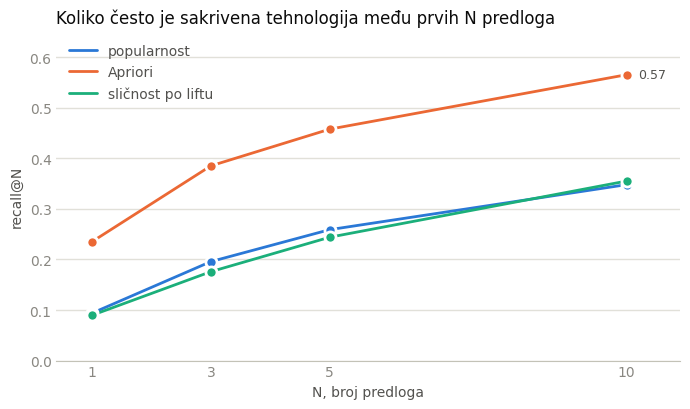

In [13]:
import matplotlib.pyplot as plt

# Boje prate model kroz sve grafike u notebooku.
BOJE = {"popularnost": "#2a78d6", "Apriori": "#eb6834", "sličnost po liftu": "#1baf7a"}
TEKST, TEKST_2, BLEDO, MREZA, OSA = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"


def uredi_osu(ax) -> None:
    """Tanka osnovna linija, svetla horizontalna mreža, bez okvira."""
    for strana in ("top", "right", "left"):
        ax.spines[strana].set_visible(False)
    ax.spines["bottom"].set_color(OSA)
    ax.tick_params(colors=BLEDO, length=0)
    ax.yaxis.grid(True, color=MREZA, linewidth=1)
    ax.set_axisbelow(True)


fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.array(NS)
for ime, boja in BOJE.items():
    y = recall.loc[ime].to_numpy()
    ax.plot(x, y, color=boja, linewidth=2, solid_capstyle="round", solid_joinstyle="round", label=ime, zorder=2)
    ax.scatter(x, y, s=64, color=boja, edgecolor="white", linewidth=2, zorder=3)

# Oznaka samo na kraju linije koja nosi priču; ostale vrednosti su u tabeli iznad.
y_apriori = recall.loc["Apriori", "recall@10"]
ax.annotate(f"{y_apriori:.2f}", (10, y_apriori), xytext=(8, 0), textcoords="offset points",
            va="center", fontsize=9, color=TEKST_2)

uredi_osu(ax)
ax.set_xticks(x)
ax.set_xlim(0.4, 10.9)
ax.set_ylim(0, recall.to_numpy().max() * 1.15)
ax.set_xlabel("N, broj predloga", color=TEKST_2)
ax.set_ylabel("recall@N", color=TEKST_2)
ax.set_title("Koliko često je sakrivena tehnologija među prvih N predloga",
             loc="left", color=TEKST, fontsize=12)
ax.legend(frameon=False, loc="upper left", labelcolor=TEKST_2)
fig.tight_layout()
fig.savefig(FIG / "preporuka_recall.png", dpi=200)
plt.show()

### Šta se vidi

- Apriori pogađa sakrivenu tehnologiju na prvom mestu 2,5 puta češće od
  popularnosti (0,235 prema 0,094), a među prvih pet 1,8 puta češće.
- Sličnost po liftu je po ukupnom recall-u na nivou popularnosti. Sekcija 8
  pokazuje da taj prosek sakriva veliku razliku između popularnih i retkih
  tehnologija.

### Da li zavisi od toga koliko kandidat zna

recall@5 prema broju tehnologija koje kandidat već zna. Grupa "8+" spaja sve
korpe sa osam i više poznatih tehnologija.

In [14]:
po_velicini = pokusaji.assign(zna=pokusaji["zna"].clip(upper=8))
tabela = (po_velicini.groupby(["zna", "model"])["pozicija"].apply(lambda p: (p <= 5).mean())
          .unstack("model")[list(MODELI)])
tabela.insert(0, "pokušaja", po_velicini[po_velicini["model"] == "popularnost"].groupby("zna").size())
tabela.index = [f"{z}+" if z == 8 else str(z) for z in tabela.index]
tabela.index.name = "zna"
print(tabela.round(3).to_string())

model  pokušaja  popularnost  Apriori  sličnost po liftu
zna                                                     
1           428        0.262    0.414              0.213
2           750        0.299    0.468              0.249
3           792        0.270    0.470              0.213
4           845        0.269    0.466              0.253
5           888        0.271    0.453              0.256
6           798        0.248    0.425              0.227
7           720        0.272    0.500              0.247
8+         4473        0.245    0.456              0.250


Rezultat malo zavisi od toga koliko kandidat zna: Apriori je između 0,41 i 0,50
za svaku veličinu ulaza. Već jedna poznata tehnologija daje dovoljno konteksta.

## 8. Više od pogađanja: pokrivenost i sklonost popularnosti

recall@N ima ugrađenu pristrasnost. Tehnologija se sakriva onoliko puta koliko se
javlja u skupu za proveru, pa se Python sakriva stotinama puta, a retke
tehnologije po nekoliko puta. Model koji uvek predlaže popularne tehnologije zato
automatski dobija dobar recall, iako nikome ne govori ništa novo.

Zato se uz recall prate još dve mere:

- pokrivenost, koliki deo tehnologija iz rečnika model predloži bar jednom
- medijana ranga popularnosti predloženih tehnologija, gde je 1 najpopularnija
  tehnologija, a veći broj znači da model predlaže ređe tehnologije

Recall se računa i posebno, prema tome koliko je sakrivena tehnologija popularna.

In [15]:
sakrivanja = pokusaji.loc[pokusaji["model"] == "popularnost", "sakrivena"].value_counts()
top20 = set(POP_RANG[:20])

print(f"različitih sakrivenih tehnologija: {len(sakrivanja)} od {len(U_RECNIKU)}")
print("najčešće sakrivane: " + ", ".join(f"{t} ({n})" for t, n in sakrivanja.head(5).items()))
print(f"medijana broja sakrivanja po tehnologiji: {sakrivanja.median():.0f}")
print(f"udeo pokušaja u kojima je sakrivena jedna od 20 najpopularnijih: "
      f"{sakrivanja[sakrivanja.index.isin(top20)].sum() / sakrivanja.sum() * 100:.1f} %")

različitih sakrivenih tehnologija: 287 od 287
najčešće sakrivane: PYTHON (598), SQL (435), AWS (382), JAVA (373), AZURE (282)
medijana broja sakrivanja po tehnologiji: 14
udeo pokušaja u kojima je sakrivena jedna od 20 najpopularnijih: 43.2 %


In [16]:
def pokrivenost(pokusaji: pd.DataFrame, velicina_recnika: int, n: int = 10) -> pd.Series:
    """Deo rečnika koji se bar jednom pojavi među prvih n predloga."""
    return (pokusaji.groupby("model", sort=False)["predlozi"]
            .apply(lambda s: len({t for p in s for t in p[:n]}) / velicina_recnika))


def medijana_ranga(pokusaji: pd.DataFrame, n: int = 10) -> pd.Series:
    """Medijana ranga popularnosti predloženih tehnologija (1 = najpopularnija)."""
    return (pokusaji.groupby("model", sort=False)["predlozi"]
            .apply(lambda s: float(np.median([POP_POZICIJA[t] + 1 for p in s for t in p[:n]]))))


sirina = pd.DataFrame({
    "recall@10": recall["recall@10"],
    "pokrivenost": pokrivenost(pokusaji, len(U_RECNIKU)),
    "medijana ranga popularnosti": medijana_ranga(pokusaji),
})
print(sirina.round(3).to_string())

                   recall@10  pokrivenost  medijana ranga popularnosti
model                                                                 
popularnost            0.348        0.073                          7.0
Apriori                0.565        0.331                          9.0
sličnost po liftu      0.355        0.993                        123.0


### recall prema popularnosti sakrivene tehnologije

Tehnologije su podeljene po rangu popularnosti u skupu za učenje: 20
najpopularnijih, rang 21 do 100, i ostale.

In [17]:
GRUPE = ["1-20", "21-100", "101+"]


def grupa_popularnosti(t: str) -> str:
    rang = POP_POZICIJA[t] + 1
    return GRUPE[0] if rang <= 20 else GRUPE[1] if rang <= 100 else GRUPE[2]


def recall_po_grupama(pokusaji: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    """recall@n posebno za popularne, srednje i retke sakrivene tehnologije."""
    imena = list(dict.fromkeys(pokusaji["model"]))
    po_grupi = pokusaji.assign(grupa=pokusaji["sakrivena"].map(grupa_popularnosti))
    tabela = (po_grupi.groupby(["grupa", "model"])["pozicija"].apply(lambda p: (p <= n).mean())
              .unstack("model").loc[GRUPE, imena])
    tabela.insert(0, "pokušaja",
                  po_grupi[po_grupi["model"] == imena[0]].groupby("grupa").size().loc[GRUPE])
    return tabela


po_popularnosti = recall_po_grupama(pokusaji)
print("recall@10 po grupi popularnosti sakrivene tehnologije:\n")
print(po_popularnosti.round(3).to_string())

recall@10 po grupi popularnosti sakrivene tehnologije:

model   pokušaja  popularnost  Apriori  sličnost po liftu
grupa                                                    
1-20        4191        0.805    0.886              0.157
21-100      3588        0.000    0.445              0.499
101+        1915        0.000    0.089              0.517


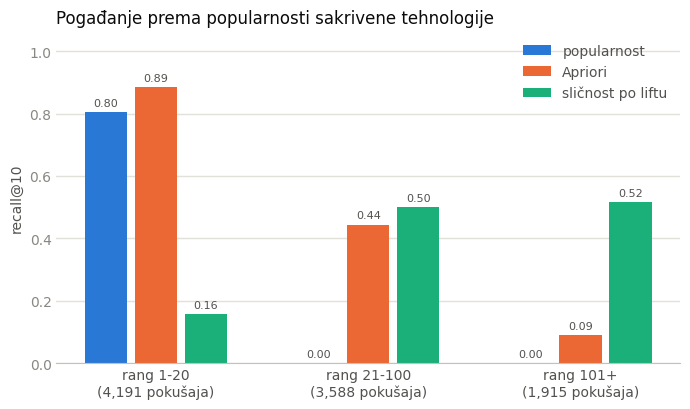

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sirina_stupca, korak = 0.2, 0.235          # razmak između stubaca je praznina, ne okvir
for j, (ime, boja) in enumerate(BOJE.items()):
    pozicije = np.arange(len(GRUPE)) + (j - 1) * korak
    vrednosti = po_popularnosti[ime].to_numpy()
    ax.bar(pozicije, vrednosti, width=sirina_stupca, color=boja, label=ime, zorder=2)
    for xp, v in zip(pozicije, vrednosti):
        ax.annotate(f"{v:.2f}", (xp, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=TEKST_2)

uredi_osu(ax)
ax.set_xticks(np.arange(len(GRUPE)))
ax.set_xticklabels([f"rang {g}\n({n:,} pokušaja)" for g, n in zip(GRUPE, po_popularnosti["pokušaja"])],
                   color=TEKST_2)
ax.set_ylim(0, po_popularnosti[list(MODELI)].to_numpy().max() * 1.2)
ax.set_ylabel("recall@10", color=TEKST_2)
ax.set_title("Pogađanje prema popularnosti sakrivene tehnologije", loc="left", color=TEKST, fontsize=12)
ax.legend(frameon=False, loc="upper right", labelcolor=TEKST_2)
fig.tight_layout()
# u radu naslov stoji u natpisu ispod slike, pa se slika snima bez njega
_naslovi = {mesto: ax.get_title(loc=mesto) for mesto in ("left", "center", "right")}
for _mesto in _naslovi:
    ax.set_title("", loc=_mesto)
fig.savefig(FIG / "preporuka_po_popularnosti.png", dpi=200)
for _mesto, _tekst in _naslovi.items():
    ax.set_title(_tekst, loc=_mesto)
plt.show()

### Šta se vidi

- Metrika je naklonjena popularnim tehnologijama. Na 20 najpopularnijih otpada
  43 % pokušaja. Python je sakriven 598 puta, a polovina tehnologija 14 puta ili
  manje.
- Popularnost pogađa samo tih 20 tehnologija i nijednu drugu.
- Apriori je najbolji za popularne tehnologije (0,89) i solidan za srednje (0,45),
  ali retke skoro nikad ne pogađa (0,09). Deo razloga je prag podrške: od 287
  tehnologija iz rečnika, 75 se ne javlja ni u jednom čestom skupu, pa ni u jednom
  pravilu.
- Sličnost po liftu je slaba baš tamo gde je najviše pokušaja, kod popularnih
  tehnologija (0,16), a najbolja kod srednjih i retkih (0,50 i 0,52). Njen ukupni
  recall je na nivou popularnosti zato što metrika najviše broji popularne
  tehnologije. Predlaže 99 % rečnika, prema 33 % kod Apriorija i 7 % kod
  popularnosti.

Dva modela se dopunjuju. Apriori odgovara na pitanje šta kandidatu najverovatnije
treba sledeće, a sličnost po liftu na pitanje šta je specifično za njegov skup
tehnologija.

## 9. Stabilnost rezultata

Sve do sada je jedna podela na učenje i proveru. Druga podela bi dala druge
firme u proveri i nešto drugačije brojeve. Da bi se videlo da razlika između
modela nije slučajnost jedne podele, ceo postupak se ponavlja pet puta: podela,
rečnik, učenje sva tri modela, provera.

Ovo nije k-fold unakrsna validacija, nego ponovljena slučajna podela (Monte
Carlo cross-validation) po firmama: svaki put se nezavisno izdvoji 20 % firmi,
pa ista firma može biti u proveri više puta, a neka nijednom.

Isti postupak se ponavlja i sa nasumičnom podelom po oglasu, da se izmeri koliko
podela po firmi menja rezultat (sekcija 2).

Ponavljanje koristi iste funkcije kao sekcije 2 do 8, pa se ponavlja tačno ono
što je gore opisano, a ne kopija koda.

In [19]:
SEEDOVI = (1, 7, 42, 123, 2026)


def nauci_sve(korpe: list[list[str]]) -> None:
    """Uči sva tri modela na zadatim korpama.  Menja globalno stanje koje koriste preporuci_*."""
    global popularnost, POP_RANG, POP_POZICIJA, PRAVILA, LIFT
    popularnost, POP_RANG, POP_POZICIJA = nauci_popularnost(korpe)
    PRAVILA = indeksiraj_pravila(nauci_pravila(korpe)[1])
    LIFT, _ = nauci_lift(korpe, popularnost)


def ceo_postupak(seed: int, po_firmi: bool, modeli: dict) -> pd.DataFrame:
    """Podela -> rečnik -> učenje -> provera, za jednu podelu."""
    uc, pr = podeli(seed, po_firmi)
    recnik = napravi_recnik(uc)
    k_uc = svedi_na_recnik(uc["korpa"], recnik)
    k_pr = svedi_na_recnik(pr["korpa"], recnik, min_duzina=2)
    nauci_sve(k_uc)
    pok = oceni_modele(modeli, k_pr)
    rez = recall_tabela(pok)
    rez["pokrivenost"] = pokrivenost(pok, len(recnik))
    rez["medijana ranga popularnosti"] = medijana_ranga(pok)
    return rez.assign(seed=seed, podela="po firmi" if po_firmi else "nasumično").reset_index()


try:
    ponavljanja = pd.concat([ceo_postupak(s, po_firmi, MODELI) for po_firmi in (True, False) for s in SEEDOVI],
                            ignore_index=True)
finally:
    nauci_sve(korpe_ucenje)   # vrati modele naučene na glavnoj podeli, za sekcije posle ove

print(f"urađeno ponavljanja: {len(ponavljanja) // len(MODELI)}")

urađeno ponavljanja: 10


In [20]:
KOLONE = ["recall@1", "recall@5", "recall@10", "pokrivenost", "medijana ranga popularnosti"]
po_firmi = ponavljanja[ponavljanja["podela"] == "po firmi"]
agregat = po_firmi.groupby("model", sort=False)[KOLONE].agg(["mean", "std"])

sazetak = pd.DataFrame({
    k: [f"{m:.1f} +/- {s:.1f}" if "ranga" in k else f"{m:.3f} +/- {s:.3f}"
        for m, s in zip(agregat[(k, "mean")], agregat[(k, "std")])]
    for k in KOLONE
}, index=agregat.index)
print("Pet podela po firmi, prosek +/- standardna devijacija:\n")
print(sazetak.to_string())

r5 = po_firmi.pivot(index="seed", columns="model", values="recall@5")
razlika = r5["Apriori"] - r5["popularnost"]
print(f"\nApriori − popularnost, recall@5, po podeli: {', '.join(f'{v:.3f}' for v in razlika)}")

Pet podela po firmi, prosek +/- standardna devijacija:

                          recall@1         recall@5        recall@10      pokrivenost medijana ranga popularnosti
model                                                                                                            
popularnost        0.088 +/- 0.006  0.250 +/- 0.012  0.344 +/- 0.013  0.077 +/- 0.005                 7.0 +/- 0.0
Apriori            0.236 +/- 0.008  0.453 +/- 0.009  0.563 +/- 0.008  0.349 +/- 0.017                 9.0 +/- 0.0
sličnost po liftu  0.085 +/- 0.005  0.246 +/- 0.009  0.363 +/- 0.011  0.989 +/- 0.006               123.2 +/- 2.2

Apriori − popularnost, recall@5, po podeli: 0.208, 0.204, 0.199, 0.195, 0.206


In [21]:
poredjenje = (ponavljanja.groupby(["model", "podela"], sort=False)[["recall@1", "recall@5"]].mean()
              .unstack("podela"))
poredjenje[("recall@5", "nasumično − po firmi")] = (poredjenje[("recall@5", "nasumično")]
                                                    - poredjenje[("recall@5", "po firmi")])
print("Prosek preko pet podela:\n")
print(poredjenje.round(3).to_string())

Prosek preko pet podela:

                  recall@1           recall@5                               
podela            po firmi nasumično po firmi nasumično nasumično − po firmi
model                                                                       
popularnost          0.088     0.085    0.250     0.245               -0.005
Apriori              0.236     0.237    0.453     0.450               -0.002
sličnost po liftu    0.085     0.089    0.246     0.255                0.009


### Šta se vidi

- Razlika između Apriorija i popularnosti u recall@5 je između 0,195 i 0,208 na
  svakoj od pet podela. Recall i pokrivenost se od podele do podele menjaju za
  manje od 0,02, pa razlika između modela nije slučajnost jedne podele.
- Nasumična podela menja recall@5 za najviše 0,009, i to u oba smera. Kao što je
  očekivano u sekciji 2, kod modela zasnovanih na brojanju podela po firmi ne
  menja rezultat.

## 10. Hibridni model

Sekcija 8 je pokazala da su Apriori i sličnost po liftu dobri na različitim
mestima: Apriori kod popularnih tehnologija, lift kod srednjih i retkih. Ako je
tako, spoj bi trebalo da bude bolji od oba.

Spajaju se mesta na listi, a ne ocene. Svaki model daje svoju listu od deset
predloga, a nova lista uzima naizmenično sa vrhova te dve, preskačući ono što je
već uzeto:

```
1. mesto  <-  Apriori, 1. sa njegove liste
2. mesto  <-  lift,    1. sa njegove liste
3. mesto  <-  Apriori, 2. sa njegove liste
4. mesto  <-  lift,    2. sa njegove liste
...
```

Spajaju se mesta, a ne ocene, zato što je pouzdanost broj između 0 i 1, dok zbir
logaritama lifta nema gornju granicu i raste sa brojem tehnologija koje kandidat
zna. Da bi se sabrale, morale bi se veštački svesti na istu skalu, a svaki takav
izbor je proizvoljan i morao bi se braniti. Mesto na listi je bez te odluke:
svejedno je kojom merom je model došao do svog prvog predloga, uzima se to što je
njegov prvi.

In [22]:
def preporuci_hibridni(zna: set[str], n: int = 10) -> list[str]:
    """Naizmenično uzima predloge Apriorija i sličnosti po liftu, preskačući ponovljene."""
    liste = (preporuci_apriori(zna, n), preporuci_lift(zna, n))
    spoj: list[str] = []
    for i in range(n):
        for lista in liste:
            if len(spoj) == n:
                return spoj
            if i < len(lista) and lista[i] not in spoj:
                spoj.append(lista[i])
    return spoj


SVI_MODELI = {**MODELI, "hibridni": preporuci_hibridni}

for zna in [{"TABLEAU"}, {"JAVA", "SPRING BOOT"}]:
    print(f"\nzna: {', '.join(sorted(zna))}")
    for ime in ("Apriori", "sličnost po liftu", "hibridni"):
        print(f"   {ime:<20}{', '.join(SVI_MODELI[ime](zna, 6))}")


zna: TABLEAU
   Apriori             SQL, PYTHON, POWER BI, R, EXCEL, SNOWFLAKE
   sličnost po liftu   ALTERYX, QLIK, LOOKER, POWER BI, COGNOS, COLLIBRA
   hibridni            SQL, ALTERYX, PYTHON, QLIK, POWER BI, LOOKER

zna: JAVA, SPRING BOOT
   Apriori             PYTHON, AWS, JENKINS, DOCKER, KUBERNETES, SPRING
   sličnost po liftu   JPA, HIBERNATE, J2EE, MAVEN, GRADLE, SPRING
   hibridni            PYTHON, JPA, AWS, HIBERNATE, JENKINS, J2EE


### Ista provera kao za ostale modele

In [23]:
pokusaji_svi = oceni_modele(SVI_MODELI, korpe_provera)

sazetak_glavni = recall_tabela(pokusaji_svi)
sazetak_glavni["pokrivenost"] = pokrivenost(pokusaji_svi, len(U_RECNIKU))
sazetak_glavni["medijana ranga popularnosti"] = medijana_ranga(pokusaji_svi)
print(sazetak_glavni.round(3).to_string())

                   recall@1  recall@3  recall@5  recall@10  pokrivenost  medijana ranga popularnosti
model                                                                                               
popularnost           0.094     0.196     0.259      0.348        0.073                          7.0
Apriori               0.235     0.385     0.457      0.565        0.331                          9.0
sličnost po liftu     0.090     0.176     0.244      0.355        0.993                        123.0
hibridni              0.235     0.391     0.471      0.600        0.976                         37.0


In [24]:
po_popularnosti_svi = recall_po_grupama(pokusaji_svi)
print("recall@10 po grupi popularnosti sakrivene tehnologije:\n")
print(po_popularnosti_svi.round(3).to_string())

recall@10 po grupi popularnosti sakrivene tehnologije:

model   pokušaja  popularnost  Apriori  sličnost po liftu  hibridni
grupa                                                              
1-20        4191        0.805    0.886              0.157     0.788
21-100      3588        0.000    0.445              0.499     0.470
101+        1915        0.000    0.089              0.517     0.430


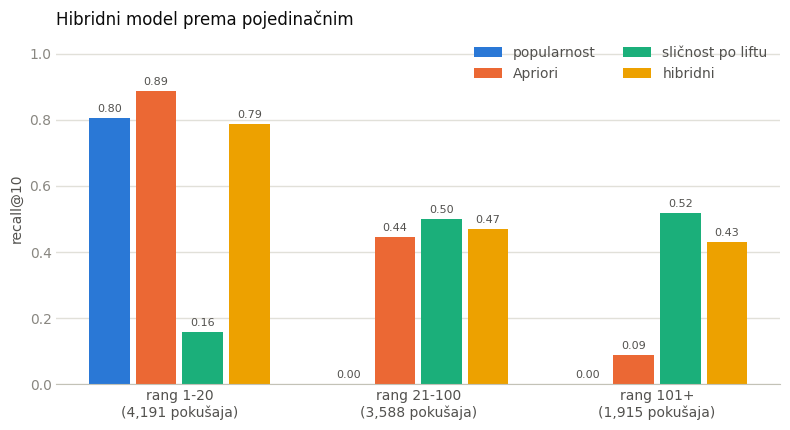

In [25]:
BOJE_4 = {**BOJE, "hibridni": "#eda100"}

fig, ax = plt.subplots(figsize=(8, 4.4))
sirina_stupca, korak = 0.17, 0.195
for j, (ime, boja) in enumerate(BOJE_4.items()):
    pozicije = np.arange(len(GRUPE)) + (j - 1.5) * korak
    vrednosti = po_popularnosti_svi[ime].to_numpy()
    ax.bar(pozicije, vrednosti, width=sirina_stupca, color=boja,
           label=ime, zorder=2)
    for xp, v in zip(pozicije, vrednosti):
        ax.annotate(f"{v:.2f}", (xp, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=TEKST_2)

uredi_osu(ax)
ax.set_xticks(np.arange(len(GRUPE)))
ax.set_xticklabels([f"rang {g}\n({n:,} pokušaja)" for g, n in zip(GRUPE, po_popularnosti_svi["pokušaja"])],
                   color=TEKST_2)
ax.set_ylim(0, po_popularnosti_svi[list(SVI_MODELI)].to_numpy().max() * 1.2)
ax.set_ylabel("recall@10", color=TEKST_2)
ax.set_title("Hibridni model prema pojedinačnim", loc="left", color=TEKST, fontsize=12)
ax.legend(frameon=False, loc="upper right", ncol=2, labelcolor=TEKST_2)
fig.tight_layout()
# u radu naslov stoji u natpisu ispod slike, pa se slika snima bez njega
_naslovi = {mesto: ax.get_title(loc=mesto) for mesto in ("left", "center", "right")}
for _mesto in _naslovi:
    ax.set_title("", loc=_mesto)
fig.savefig(FIG / "preporuka_hibridni.png", dpi=200)
for _mesto, _tekst in _naslovi.items():
    ax.set_title(_tekst, loc=_mesto)
plt.show()

### Stabilnost hibridnog modela

Isti postupak i iste podele kao u sekciji 9. Za tri pojedinačna modela rezultati
su već izračunati tamo, pa se ovde dodaje samo hibridni model.

In [26]:
try:
    hibridni_ponavljanja = pd.concat(
        [ceo_postupak(s, True, {"hibridni": preporuci_hibridni}) for s in SEEDOVI], ignore_index=True)
finally:
    nauci_sve(korpe_ucenje)   # vrati modele naučene na glavnoj podeli

uporedo = pd.concat([po_firmi, hibridni_ponavljanja], ignore_index=True)
agregat_svi = uporedo.groupby("model", sort=False)[KOLONE].agg(["mean", "std"])

print("Pet podela po firmi, prosek +/- standardna devijacija:\n")
print(pd.DataFrame({
    k: [f"{m:.1f} +/- {s:.1f}" if "ranga" in k else f"{m:.3f} +/- {s:.3f}"
        for m, s in zip(agregat_svi[(k, "mean")], agregat_svi[(k, "std")])]
    for k in KOLONE
}, index=agregat_svi.index).to_string())

prosek = uporedo.groupby("model")[KOLONE].mean()
print("\nhibridni − Apriori:")
for k in ["recall@1", "recall@5", "recall@10", "pokrivenost"]:
    print(f"   {k:<12} {prosek.loc['hibridni', k] - prosek.loc['Apriori', k]:+.3f}")

po_podeli = uporedo.pivot(index="seed", columns="model", values="recall@10")
razlike = po_podeli["hibridni"] - po_podeli["Apriori"]
print(f"\nhibridni − Apriori, recall@10, po podeli: {', '.join(f'{v:+.3f}' for v in razlike)}")

Pet podela po firmi, prosek +/- standardna devijacija:

                          recall@1         recall@5        recall@10      pokrivenost medijana ranga popularnosti
model                                                                                                            
popularnost        0.088 +/- 0.006  0.250 +/- 0.012  0.344 +/- 0.013  0.077 +/- 0.005                 7.0 +/- 0.0
Apriori            0.236 +/- 0.008  0.453 +/- 0.009  0.563 +/- 0.008  0.349 +/- 0.017                 9.0 +/- 0.0
sličnost po liftu  0.085 +/- 0.005  0.246 +/- 0.009  0.363 +/- 0.011  0.989 +/- 0.006               123.2 +/- 2.2
hibridni           0.236 +/- 0.008  0.464 +/- 0.009  0.594 +/- 0.006  0.976 +/- 0.006                37.2 +/- 0.4

hibridni − Apriori:
   recall@1     +0.000
   recall@5     +0.012
   recall@10    +0.031
   pokrivenost  +0.627

hibridni − Apriori, recall@10, po podeli: +0.025, +0.028, +0.035, +0.031, +0.037


### Šta se vidi

Hibridni model je bolji od Apriorija po svakoj meri koja je unapred postavljena:

- `recall@10` je veći na svakoj od pet podela, za 0,025 do 0,037
- `recall@5` je veći za 0,012
- pokrivenost raste sa 35 % na 98 % rečnika

`recall@1` se ne menja (0,236), jer je prvo mesto na listi uvek Apriorijevo.

Cena je merljiva i ide tamo gde je i očekivana: kod 20 najpopularnijih
tehnologija pogađanje pada sa 0,886 na 0,788, jer pola mesta na listi pripada
liftu, koji popularne tehnologije retko predlaže. Medijana ranga popularnosti
predloga pomera se sa 9 na 37, što znači da hibridni model predlaže osetno
specifičnije tehnologije.

Nalaz sekcije je da pouzdanost i lift mere različite stvari i da se dopunjuju.

Jedno ograničenje ostaje i u hibridnom modelu. Polovina predloga dolazi od lifta,
a lift ne razlikuje tehnologiju koja dopunjuje ono što kandidat zna od one koja
ga zamenjuje. Vidi se u primeru na početku ove sekcije: uz Tableau se predlažu
Alteryx, Qlik i Looker, a to su konkurentski alati iste namene. Uz Javu i Spring
Boot predlozi su JPA, Hibernate i J2EE, što jesu dopune. Sledeća sekcija to meri.

## 11. Zamena ili dopuna

Modeli uče iz toga što se dve tehnologije javljaju u istom oglasu. Ali oglas
često traži jednu od nekoliko mogućnosti: "iskustvo sa Tableau, Power BI ili
Qlik". Za model to izgleda isto kao da se tehnologije koriste zajedno.

Razlika je važna za tumačenje preporuke. "Uz Spring Boot nauči Hibernate" znači
dodati veštinu koja nedostaje. "Uz Tableau nauči Qlik" znači naučiti zamenu za
ono što kandidat već zna. Oba saveta povećavaju broj oglasa na koje kandidat
odgovara, ali nisu ista vrsta saveta.

Merenje: za parove za koje se unapred zna da su zamene, alati iste namene, i za
one za koje se zna da su dopune, meri se koliko često oglas između njihova dva
naziva stavlja reč "or".

Dva ograničenja:

- parovi su izabrani ručno, pa ovo pokazuje da mehanizam postoji, a ne koliko je
  ukupno rasprostranjen
- traži se samo reč "or", pa nabrajanja poput "Tableau, Power BI, Qlik" ostaju
  neprimećena, i izmereni udeo je donja granica

In [27]:
import re

PAROVI_ZA_PROVERU = [
    # očekivane zamene, alati iste namene
    ("zamena", "TABLEAU", "POWER BI"), ("zamena", "TABLEAU", "QLIK"), ("zamena", "TABLEAU", "LOOKER"),
    ("zamena", "REACT", "VUE"), ("zamena", "REACT", "ANGULAR"),
    ("zamena", "ANSIBLE", "CHEF"), ("zamena", "ANSIBLE", "PUPPET"),
    ("zamena", "AWS", "AZURE"), ("zamena", "AWS", "GCP"),
    # očekivane dopune, alati koji se koriste zajedno
    ("dopuna", "REACT", "REDUX"), ("dopuna", "JAVA", "SPRING BOOT"),
    ("dopuna", "DOCKER", "KUBERNETES"), ("dopuna", "AWS", "TERRAFORM"),
    ("dopuna", "PANDAS", "NUMPY"),
]

# Kako se naziv piše u tekstu oglasa; kanonski naziv iz 02_analiza nije dovoljan.
OBLICI = {
    "TABLEAU": r"tableau", "POWER BI": r"power\s?bi", "QLIK": r"qlik\w*", "LOOKER": r"looker",
    "REACT": r"react(?:\.?js)?", "VUE": r"vue(?:\.?js)?", "ANGULAR": r"angular(?:js)?", "REDUX": r"redux",
    "ANSIBLE": r"ansible", "CHEF": r"chef", "PUPPET": r"puppet",
    "AWS": r"aws|amazon web services", "AZURE": r"azure", "GCP": r"gcp|google cloud",
    "JAVA": r"java(?!script)", "SPRING BOOT": r"spring\s?boot",
    "DOCKER": r"docker", "KUBERNETES": r"kubernetes|k8s",
    "TERRAFORM": r"terraform", "PANDAS": r"pandas", "NUMPY": r"numpy",
}

IZRAZ = {t: re.compile(rf"\b(?:{o})\b") for t, o in OBLICI.items()}
ILI = re.compile(r"\bor\b")
PROZOR = 60   # najviše toliko znakova između dva naziva da bi se smatrali istim nabrajanjem

opisi = pd.read_csv("data/raw/postings.csv", usecols=["job_id", "description"]).set_index("job_id")["description"]
tekst = it.assign(opis=it["job_id"].map(opisi).fillna("").str.lower())


def meri_par(a: str, b: str) -> dict:
    """Koliko oglasa koji traže obe tehnologije ih pominje blizu jedne druge, i sa "or" između."""
    oba = tekst[tekst["tech"].apply(lambda l: l is not None and a in l and b in l)]
    blizu = sa_ili = 0
    for opis in oba["opis"]:
        mesta_a = [m.span() for m in IZRAZ[a].finditer(opis)]
        mesta_b = [m.span() for m in IZRAZ[b].finditer(opis)]
        je_blizu = je_ili = False
        for pocetak_a, kraj_a in mesta_a:
            for pocetak_b, kraj_b in mesta_b:
                # deo teksta između baš ta dva pojavljivanja, bez obzira koje je prvo
                od, do = (kraj_a, pocetak_b) if kraj_a <= pocetak_b else (kraj_b, pocetak_a)
                if 0 <= do - od <= PROZOR:
                    je_blizu = True
                    je_ili |= bool(ILI.search(opis[od:do]))
        blizu += je_blizu
        sa_ili += je_ili
    n = len(oba)
    return {"oglasa zajedno": n,
            "blizu u tekstu %": round(100 * blizu / n, 1) if n else float("nan"),
            "sa "or" između %": round(100 * sa_ili / n, 1) if n else float("nan")}


zamene = pd.DataFrame([{"očekivano": vrsta, "par": f"{a} + {b}", **meri_par(a, b)}
                       for vrsta, a, b in PAROVI_ZA_PROVERU])
print(zamene.to_string(index=False))
print("\nprosek po vrsti para:")
print(zamene.groupby("očekivano")[["blizu u tekstu %", "sa "or" između %"]].mean().round(1).to_string())

očekivano                 par  oglasa zajedno  blizu u tekstu %  sa 
   zamena  TABLEAU + POWER BI             252              88.1 14.3
   zamena      TABLEAU + QLIK              32              90.6 12.5
   zamena    TABLEAU + LOOKER              27              96.3 14.8
   zamena         REACT + VUE              47              76.6 19.1
   zamena     REACT + ANGULAR             239              87.4 17.2
   zamena      ANSIBLE + CHEF              97              85.6 12.4
   zamena    ANSIBLE + PUPPET             106              88.7 17.9
   zamena         AWS + AZURE             908              93.0 15.3
   zamena           AWS + GCP             567              95.1 27.2
   dopuna       REACT + REDUX              79              77.2  7.6
   dopuna  JAVA + SPRING BOOT             343              65.6  4.1
   dopuna DOCKER + KUBERNETES             665              83.0  3.0
   dopuna     AWS + TERRAFORM             381              31.2  4.2
   dopuna      PANDAS + NUMPY     

### Šta se vidi

Kod parova koji su zamene, oglas između njihova dva naziva stavlja "or" u
prosečno 16,7 % slučajeva, od 12,4 % do 27,2 %. Kod parova koji su dopune, u
3,8 %, od 0 % do 7,6 %. Razlika je oko četiri i po puta, i nijedan par jedne
vrste ne ulazi u opseg druge.

Isto se vidi i po tome koliko se nazivi uopšte pominju blizu jedan drugog: 89 %
kod zamena, 68 % kod dopuna. Zamene se navode u istoj rečenici, kao spisak
mogućnosti, a dopune razdvojeno, svaka na svom mestu u opisu posla.

Pošto merenje hvata samo reč "or", a ne i nabrajanja poput "Tableau, Power BI,
Qlik", pravi udeo zamena je veći od izmerenog.

Zaključak za tumačenje preporuke: modeli odgovaraju na pitanje šta poslodavci
traže uz ono što kandidat zna, a ne na pitanje šta se tehnički dopunjuje. Oba
saveta povećavaju broj oglasa na koje kandidat odgovara, ali "nauči Qlik uz
Tableau" znači proširiti se unutar iste uloge, a "nauči Hibernate uz Spring Boot"
znači popuniti prazninu u istom poslu. Model tu razliku ne vidi.

## 12. Preporuke i čuvanje rezultata

Do sada su modeli učeni samo na skupu za učenje, jer je trebalo pošteno izmeriti
koliko pogađaju. Merenje je gotovo i brojevi su zapisani.

Za upotrebu se model uči na svim IT oglasima. To je uobičajen postupak: provera
se radi na izdvojenom delu, a konačan model koristi sve podatke. Rečnik se pri
tome računa ponovo, na celom skupu.

Sve posle ove tačke koristi model naučen na svim oglasima.

In [28]:
U_RECNIKU_SVE = napravi_recnik(it)
korpe_sve = svedi_na_recnik(it["korpa"], U_RECNIKU_SVE)

nauci_sve(korpe_sve)
cesti_sve, pravila_sve = nauci_pravila(korpe_sve)
lift_sve, parovi_sve = nauci_lift(korpe_sve, popularnost)

print(f"korpi: {len(korpe_sve):,} | rečnik: {len(U_RECNIKU_SVE)} tehnologija "
      f"(prema {len(U_RECNIKU)} na skupu za učenje)")
print(f"pravila: {len(pravila_sve):,} | parova sa liftom: {sum(len(v) for v in lift_sve.values()) // 2:,}")

korpi: 9,868 | rečnik: 280 tehnologija (prema 287 na skupu za učenje)
pravila: 3,921 | parova sa liftom: 7,737


### Preporuke za nekoliko polaznih skupova

In [29]:
PRIMERI = [{"PYTHON", "SQL"}, {"JAVA", "SPRING BOOT"}, {"JAVASCRIPT", "REACT"},
           {"AWS", "TERRAFORM"}, {"ACTIVE DIRECTORY", "WINDOWS"}, {"TABLEAU", "EXCEL"}]

for zna in PRIMERI:
    print(f"\nzna: {', '.join(sorted(zna))}")
    for ime in SVI_MODELI:
        print(f"   {ime:<20}{', '.join(SVI_MODELI[ime](zna, 5))}")


zna: PYTHON, SQL
   popularnost         AWS, JAVA, AZURE, JAVASCRIPT, KUBERNETES
   Apriori             AWS, JAVA, R, TABLEAU, AZURE
   sličnost po liftu   R, PANDAS, AIRFLOW, DBT, NUMPY
   hibridni            AWS, R, JAVA, PANDAS, AIRFLOW

zna: JAVA, SPRING BOOT
   popularnost         PYTHON, SQL, AWS, AZURE, JAVASCRIPT
   Apriori             PYTHON, AWS, JENKINS, DOCKER, ANGULAR
   sličnost po liftu   JPA, HIBERNATE, J2EE, JUNIT, MAVEN
   hibridni            PYTHON, JPA, AWS, HIBERNATE, JENKINS

zna: JAVASCRIPT, REACT
   popularnost         PYTHON, SQL, AWS, JAVA, AZURE
   Apriori             CSS, HTML, ANGULAR, NODE.JS, AWS
   sličnost po liftu   SASS, REDUX, WEBPACK, VUE, JEST
   hibridni            CSS, SASS, HTML, REDUX, ANGULAR

zna: AWS, TERRAFORM
   popularnost         PYTHON, SQL, JAVA, AZURE, JAVASCRIPT
   Apriori             PYTHON, KUBERNETES, AZURE, DOCKER, ANSIBLE
   sličnost po liftu   CLOUDFORMATION, EKS, CLOUDWATCH, ECS, VPC
   hibridni            PYTHON, CLOUDFORMAT

### Šta se upisuje na disk

`04_plate.ipynb` spaja preporuku sa platom, pa mu trebaju pravila i lift tabela,
a ne ponovno računanje. Uz njih se čuva i tabela popularnosti, da se zna šta je
osnovni model, i tabela izmerenih rezultata.

In [30]:
pravila_za_disk = pd.DataFrame({
    "uslov": pravila_sve["antecedents"].apply(lambda s: " + ".join(sorted(s))),
    "preporuka": pravila_sve["consequents"].apply(lambda s: next(iter(s))),
    "podrska": pravila_sve["support"],
    "pouzdanost": pravila_sve["confidence"],
    "lift": pravila_sve["lift"],
}).sort_values("pouzdanost", ascending=False)

lift_za_disk = pd.DataFrame(
    [{"tehnologija_a": a, "tehnologija_b": b, "zajedno": parovi_sve[(a, b)], "lift": v}
     for (a, b) in parovi_sve if parovi_sve[(a, b)] >= MIN_PAR for v in [lift_sve[a][b]]]
).sort_values("lift", ascending=False)

popularnost_za_disk = pd.DataFrame({
    "tehnologija": POP_RANG,
    "oglasa": [popularnost[t] for t in POP_RANG],
    "udeo": [popularnost[t] / len(korpe_sve) for t in POP_RANG],
}).reset_index(names="rang").assign(rang=lambda d: d["rang"] + 1)

rezultati_za_disk = uporedo.groupby("model", sort=False)[KOLONE].agg(["mean", "std"])
rezultati_za_disk.columns = [f"{a} ({b})" for a, b in rezultati_za_disk.columns]

for naziv, tabela in [("preporuka_pravila", pravila_za_disk),
                      ("preporuka_lift", lift_za_disk),
                      ("preporuka_popularnost", popularnost_za_disk)]:
    tabela.to_parquet(INTERIM / f"{naziv}.parquet", index=False)
    print(f"{naziv + '.parquet':<34} {len(tabela):>7,} redova")

rezultati_za_disk.round(4).to_csv(INTERIM / "preporuka_rezultati.csv")
print(f"{'preporuka_rezultati.csv':<34} {len(rezultati_za_disk):>7,} redova")

preporuka_pravila.parquet            3,921 redova
preporuka_lift.parquet               7,737 redova
preporuka_popularnost.parquet          280 redova
preporuka_rezultati.csv                  4 redova
